In [4]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Set random seed for reproducibility
torch.manual_seed(42)
#1. Define the input tokens and basic dimensions
tokens = ["Hey", "How", "are"]
seq_len = len(tokens)
#Let's define embedding dimension (d_model) and projection dimensions (d_k, d_v)
d_model = 16
d_k = 8
d_v = 8
#2. Initialize toy embeddings for our tokens
embeddings = torch.randn(seq_len, d_model)
print("Input embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb[:4].tolist()}...(dimension: {d_model})")
#3 Define project weights
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)
# Compute Q, K, V
Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)

Input embeddings (Hidden States):
Hey: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]...(dimension: 16)
How: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]...(dimension: 16)
are: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]...(dimension: 16)
Queries (Q) Shape: torch.Size([3, 8])
Keys (K) Shape: torch.Size([3, 8])
Values (V) Shape: torch.Size([3, 8])


In [6]:
#4. Raw Attention Score (Q * k^T)
atten_scores = torch.matmul(Q, K.transpose(0,1))
#5. Attention Distribution (Softmax)
atten_distribution = F.softmax(atten_scores, dim=-1)
print("Raw Attention Scores (Q * K^T):\n", atten_scores.numpy())
print("\nAttention Distribution (Softmaxed):\n", atten_distribution.numpy())

Raw Attention Scores (Q * K^T):
 [[-10.705313 -11.606056  62.89357 ]
 [-84.69232   26.995045   6.62294 ]
 [ 69.42341    5.606927 -28.202374]]

Attention Distribution (Softmaxed):
 [[1.0874531e-32 4.4179772e-33 1.0000000e+00]
 [0.0000000e+00 1.0000000e+00 1.4207163e-09]
 [1.0000000e+00 1.9268761e-28 3.9937006e-43]]


In [7]:
#6. Calculate Final Attention Output Vectors
attention_output = torch.matmul(atten_distribution, V)
print("Final Attention Output Shape:\n", attention_output.shape)
for token, val in zip(tokens, attention_output):
    print(f"{token} attention vector: {val.tolist()}")


Final Attention Output Shape:
 torch.Size([3, 8])
Hey attention vector: [-0.28153765201568604, 2.5002551078796387, -4.627270221710205, -0.3331648111343384, -2.7299487590789795, 0.5726194381713867, 1.9096590280532837, 3.625087022781372]
How attention vector: [1.205305814743042, -0.20463502407073975, 0.6646873950958252, 2.9705708026885986, 0.8537550568580627, 0.4841350317001343, -8.405143737792969, 4.908855438232422]
are attention vector: [-2.911343574523926, -7.731362819671631, 4.0331196784973145, -6.461052894592285, -1.3542560338974, 5.622637748718262, -0.03210878372192383, -7.555790901184082]


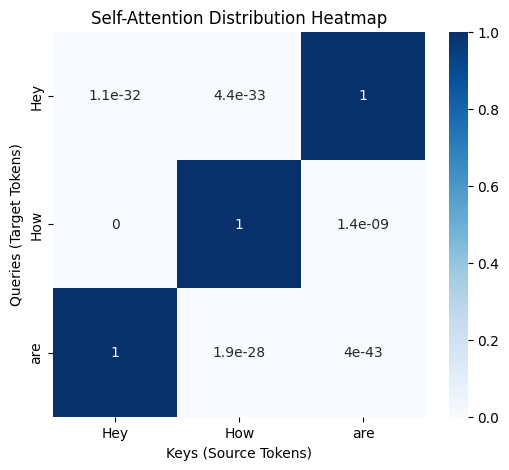

In [8]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    atten_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin = 0,
    vmax =1
)
plt.title("Self-Attention Distribution Heatmap")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.show()

In [12]:
# Explicitly show the math for step-by-step computation
for i, q_token in enumerate(tokens):
  print(f"\n--- Calculations for Query token: '{q_token}' ---")
  q_vec = Q[i]
  #1. Compute raw dot product with all keys
  raw_scores = []
  scaled_scores = []
  for j, k_token in enumerate(tokens):
    k_vec = K[j]
    dot_product = torch.dot(q_vec, k_vec).item()
    scaled_dot_product = dot_product / (d_k ** 0.5)
    raw_scores.append(dot_product)
    scaled_scores.append(scaled_dot_product)
    print(f"Key '{k_token}': Raw Dot Product = {dot_product:.4f}, Scaled (/{d_k ** 0.5:.2f}) = {scaled_dot_product:.4f}")

  #2 Compute Softmax manually to show distribution
  exp_scores = np.exp(scaled_scores)
  sum_exp = np.sum(exp_scores)
  probabilities = exp_scores / sum_exp

  print("\n--- Softmax Distribution ---")
  for j, k_token in enumerate(tokens):
    print(f" {k_token}:exp({scaled_scores[j]:.4f}) / sum_exp = {probabilities[j]:.4e}")


--- Calculations for Query token: 'Hey' ---
Key 'Hey': Raw Dot Product = -10.7053, Scaled (/2.83) = -3.7849
Key 'How': Raw Dot Product = -11.6061, Scaled (/2.83) = -4.1034
Key 'are': Raw Dot Product = 62.8936, Scaled (/2.83) = 22.2362

--- Softmax Distribution ---
 Hey:exp(-3.7849) / sum_exp = 5.0022e-12
 How:exp(-4.1034) / sum_exp = 3.6380e-12
 are:exp(22.2362) / sum_exp = 1.0000e+00

--- Calculations for Query token: 'How' ---
Key 'Hey': Raw Dot Product = -84.6923, Scaled (/2.83) = -29.9433
Key 'How': Raw Dot Product = 26.9950, Scaled (/2.83) = 9.5442
Key 'are': Raw Dot Product = 6.6229, Scaled (/2.83) = 2.3416

--- Softmax Distribution ---
 Hey:exp(-29.9433) / sum_exp = 7.0875e-18
 How:exp(9.5442) / sum_exp = 9.9926e-01
 are:exp(2.3416) / sum_exp = 7.4407e-04

--- Calculations for Query token: 'are' ---
Key 'Hey': Raw Dot Product = 69.4234, Scaled (/2.83) = 24.5449
Key 'How': Raw Dot Product = 5.6069, Scaled (/2.83) = 1.9823
Key 'are': Raw Dot Product = -28.2024, Scaled (/2.83) = -

In [14]:
# Define multi-head attention dimensions
num_heads = 2
d_k_head = 8
d_v_head = 8

#Initialize MHA weights
W_q_mha = torch.randn(d_model, d_model)
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)
#1 Linear Projections
Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)
#2 Reshape to split into heads
Q_Split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
K_Split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
V_Split = V_mha.view(seq_len, num_heads, d_v_head).transpose(0,1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_Split.shape)
print("Split Keys Shape (num_heads, seq_len, d_k_head):", K_Split.shape)
print("Split Values Shape (num_heads, seq_len, d_v_head):", V_Split.shape)

Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Keys Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Values Shape (num_heads, seq_len, d_v_head): torch.Size([2, 3, 8])


In [18]:
#3 Compute attention score & attention for each head independently
scores = torch.matmul(Q_Split, K_Split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_Split)
#4 Concatinate head outputs
concat_output = head_outputs.transpose(0, 1).contiguous().view(seq_len, d_model)
#5 Final linear projection
final_output = torch.matmul(concat_output, W_o)
print("Attention Distribution Shape (for all heads):", distributions.shape)
print("Concatenated Output Shape:", concat_output.shape)
print("Final Multi-head Attention Output Shape:", final_output.shape)

Attention Distribution Shape (for all heads): torch.Size([2, 3, 3])
Concatenated Output Shape: torch.Size([3, 16])
Final Multi-head Attention Output Shape: torch.Size([3, 16])


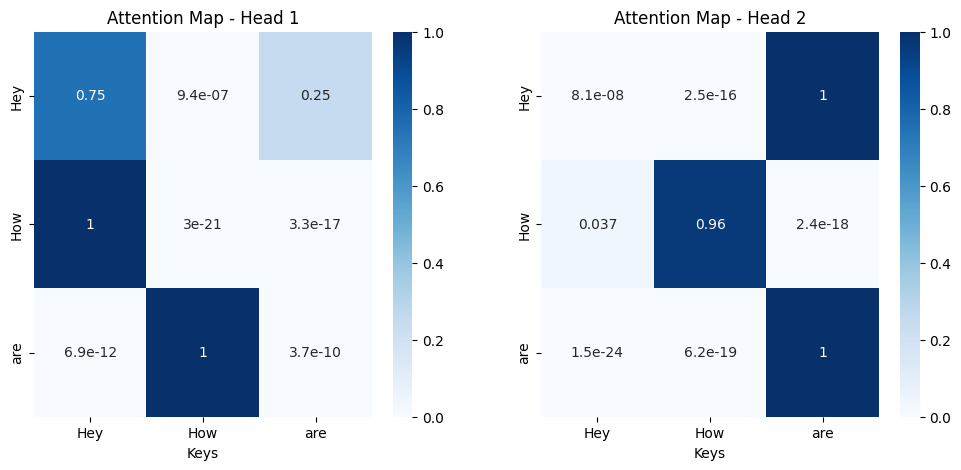

In [17]:
# Let's visualize the attention maps for both heads side-by-side
fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))
for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(),
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmax=1,
        vmin=0,
        ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h+1}")
    axes[h].set_xlabel("Keys")